# BiciLogic 04 · Stable delivery zones (districting)

In notebook 03 the VRP produced balanced routes that were *roughly* geographic territories - but **recomputed every day**. With different orders each morning, a courier would get a different area, losing the local knowledge that makes them fast and safe.

**Districting** fixes this: pre-partition the city into **stable** zones, one per courier, that are

- **balanced** (equal expected workload),
- **contiguous** (a connected area, not scattered),
- **compact** (short internal travel),
- **robust** (stay balanced as daily demand fluctuates).

This notebook starts with the naive baseline and exposes exactly why it is not enough.

In [1]:
import sys
sys.path.append("../src")

import osmnx as ox
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

ox.settings.use_cache = True
G = ox.graph_from_place("Ixelles, Brussels, Belgium", network_type="bike", simplify=True)
Gp = ox.project_graph(G)
scc = max(nx.strongly_connected_components(Gp), key=len)
Gs = Gp.subgraph(scc).copy()
nodes = list(Gs.nodes)
coords = np.array([[Gs.nodes[n]["x"], Gs.nodes[n]["y"]] for n in nodes])

## 1. A spatial demand model

Real zones should reflect *where demand is*, not just geometry. We simulate demand as **3 hotspots + a uniform background** (think: commercial clusters plus scattered orders). Each demand point is a delivery location.

In [2]:
rng = np.random.default_rng(3)
hot = coords[rng.choice(len(nodes), size=3, replace=False)]
d_near = np.sqrt(((coords[:, None, :] - hot[None, :, :]) ** 2).sum(-1)).min(axis=1)
w = np.exp(-d_near / 500.0) + 0.15      # clustered demand + background
w /= w.sum()
demand_idx = rng.choice(len(nodes), size=180, replace=False, p=w)
demand_xy = coords[demand_idx]
print("demand points:", len(demand_xy))

demand points: 180


## 2. Baseline: k-means on coordinates

points per zone: [75, 54, 51] | imbalance max/min = 1.47


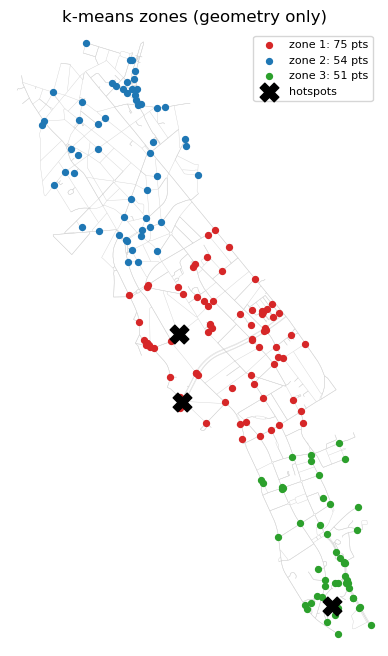

In [3]:
k = 3
km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(demand_xy)
labels = km.labels_
counts = np.bincount(labels, minlength=k)
print("points per zone:", counts.tolist(),
      f"| imbalance max/min = {counts.max()/counts.min():.2f}")

fig, ax = ox.plot_graph(Gs, node_size=0, edge_linewidth=0.3, edge_color="lightgray",
                        bgcolor="white", show=False, close=False)
colors = ["tab:red", "tab:blue", "tab:green"]
for z in range(k):
    m = labels == z
    ax.scatter(demand_xy[m, 0], demand_xy[m, 1], s=18, c=colors[z], zorder=4,
               label=f"zone {z+1}: {counts[z]} pts")
ax.scatter(hot[:, 0], hot[:, 1], marker="X", s=180, c="black", zorder=6, label="hotspots")
ax.legend(loc="upper right", fontsize=8)
ax.set_title("k-means zones (geometry only)")
plt.show()

## 3. Why this is not enough

The picture looks tidy, but it fails the requirements:

1. **Imbalanced** - k-means minimizes within-cluster spread, *not* equal workload. Here one zone carries far more points than another (a courier overloaded daily).
2. **Euclidean, not road distance** - it ignores one-ways, the canal, rail lines and big axes (e.g. Avenue Louise) that a bike must actually follow.
3. **No contiguity guarantee** - compact blobs happen to be connected here, but nothing enforces it; with barriers a zone could end up split.
4. **Static, not robust** - it fits *one* demand snapshot. Tomorrow's orders differ, so the balance (and even the shape) would drift.

**The next notebooks address these in order:** notebook 05 assigns demand by **road distance** and balances the zones; notebook 06 balances the **routed workload** directly. Still open: **contiguity**, and **robustness** - zones that stay fixed and balanced *in expectation*, with low variance under day-to-day demand.